# Paso 13: definición de segmento, filtro de 0,5 Hz y prueba de oclusión

Resuelve tres de las cuatro observaciones nuevas en una sola corrida, porque las tres parten de la misma base.

- **Segmento anormal más exigente.** Hoy basta un latido ectópico en 10 s. Se recalcula la Tabla 5 exigiendo **dos o más**, que es el criterio clínicamente defendible, y se comparan las dos definiciones.
- **Filtro de 0,5 Hz.** Se repite el entrenamiento con la frecuencia de corte recomendada para ECG diagnóstico y se compara con la de 1 Hz de la plataforma.
- **Prueba de oclusión.** Se anulan por separado el complejo QRS, el segmento ST-T y la zona de la onda P, y se mide cuánto cae la probabilidad de la clase. Convierte la afirmación sobre la repolarización en una medición causal y no solo en una atribución.

Además genera la **Figura 2 nueva** con latidos individuales de pacientes distintos en lugar del promedio.

Usa la misma partición por paciente del paso 11 y 12. **Activa la T4 GPU.** Tarda unos 35 minutos.

## 1. Instalar y descargar

In [ ]:
!pip install wfdb xgboost -q
import wfdb, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, recall_score, precision_score
from xgboost import XGBClassifier

wfdb.dl_database('mitdb', dl_dir='mitdb')
print('Descarga lista')

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

## 2. Extracción, parametrizada por la frecuencia de corte

La única diferencia respecto de los cuadernos anteriores es que `fc` ahora es argumento, para poder construir el mismo conjunto con 1 Hz y con 0,5 Hz.

In [ ]:
DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,213,214,219,221,222,228,231,232,233,234]
AAMI = {'N':'N','L':'N','R':'N','e':'N','j':'N','A':'S','a':'S','J':'S','S':'S','V':'V','E':'V','F':'F'}
CODIGOS_LATIDO = set('NLRejAaJSVEF/fQ')
CLASES = ['N','S','V','F']
FS, ANTES, DESPUES = 360, 90, 162
VENTANA_SEG = 10
MUESTRAS_SEG = FS * VENTANA_SEG

def filtro_pasa_altas(x, fs=FS, fc=1.0):
    alpha = np.exp(-2*np.pi*fc/fs)
    return x - lfilter([1-alpha], [1, -alpha], x)

def extraer_latidos(num, fc):
    ruta = f'mitdb/{num}'
    rec = wfdb.rdrecord(ruta); ann = wfdb.rdann(ruta, 'atr')
    canal = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    x = filtro_pasa_altas(rec.p_signal[:, canal], fc=fc); x = (x - x.mean())/x.std()
    pos = np.array([p for p, s in zip(ann.sample, ann.symbol) if s in CODIGOS_LATIDO])
    sim = [s for s in ann.symbol if s in CODIGOS_LATIDO]
    rr = np.diff(pos)/FS; rr_medio = rr.mean()
    V, R, Y, P, G = [], [], [], [], []
    for i in range(1, len(pos)-1):
        if sim[i] not in AAMI: continue
        r = pos[i]
        if r-ANTES < 0 or r+DESPUES > len(x): continue
        V.append(x[r-ANTES : r+DESPUES])
        R.append([rr[i-1], rr[i], rr[max(0,i-10):i].mean(), rr[i-1]/rr_medio, rr[i]/rr_medio])
        Y.append(AAMI[sim[i]]); P.append(int(r)); G.append(int(num))
    return V, R, Y, P, G

def construir(lista, fc):
    V, R, Y, P, G = [], [], [], [], []
    for n in lista:
        v, r, y, p, g = extraer_latidos(n, fc)
        V += v; R += r; Y += y; P += p; G += g
    return (np.array(V, dtype='float32'), np.array(R, dtype='float32'),
            np.array(Y), np.array(P), np.array(G))

a_numero = {c:i for i,c in enumerate(CLASES)}
datos = {}
for fc in [1.0, 0.5]:
    Ve, Re, ye, _,  rege = construir(DS1, fc)
    Vp, Rp, yp, pp, regp = construir(DS2, fc)
    datos[fc] = dict(Ve=Ve, Re=Re, ye=np.array([a_numero[k] for k in ye]), rege=rege,
                     Vp=Vp, Rp=Rp, yp=np.array([a_numero[k] for k in yp]), pos=pp, regp=regp)
    print(f'fc = {fc} Hz  ->  DS1: {len(ye)} latidos | DS2: {len(yp)} latidos')

fc = 1.0 Hz  ->  DS1: 50969 latidos | DS2: 49661 latidos
fc = 0.5 Hz  ->  DS1: 50969 latidos | DS2: 49661 latidos


## 3. La misma partición por paciente (112, 124, 205 y 223)

In [ ]:
VAL = [112, 124, 205, 223]
for fc in datos:
    d = datos[fc]
    m = np.isin(d['rege'], VAL)
    d['Vtr'], d['Rtr'], d['ytr'] = d['Ve'][~m], d['Re'][~m], d['ye'][~m]
    d['Vva'], d['Rva'], d['yva'] = d['Ve'][m],  d['Re'][m],  d['ye'][m]
print('Entrenamiento:', len(datos[1.0]['ytr']), '| validacion:', len(datos[1.0]['yva']))
print('>>> Deben coincidir con el paso 12 <<<')

Entrenamiento: 41558 | validacion: 9411
>>> Deben coincidir con el paso 12 <<<


## 4. Red convolucional, con 1 Hz y con 0,5 Hz

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def armar():
    ef = keras.Input(shape=(252, 1))
    x = layers.Conv1D(32, 7, activation='relu', padding='same')(ef)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 3, activation='relu', padding='same')(x)
    x = layers.GlobalAveragePooling1D()(x)
    er = keras.Input(shape=(5,))
    z = layers.concatenate([x, er])
    z = layers.Dense(64, activation='relu')(z)
    z = layers.Dropout(0.3)(z)
    m = keras.Model([ef, er], layers.Dense(4, activation='softmax')(z))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def entrenar(d, semilla=0):
    keras.utils.set_random_seed(semilla)
    pesos = {i: w for i, w in enumerate(
        compute_class_weight('balanced', classes=np.arange(4), y=d['ytr']))}
    m = armar()
    m.fit([d['Vtr'][..., None], d['Rtr']], d['ytr'],
          validation_data=([d['Vva'][..., None], d['Rva']], d['yva']),
          epochs=40, batch_size=256, class_weight=pesos,
          callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8,
                                                   restore_best_weights=True),
                     keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)],
          verbose=0)
    return m, m.predict([d['Vp'][..., None], d['Rp']], verbose=0)

filas = []
for fc in [1.0, 0.5]:
    d = datos[fc]
    m, prob = entrenar(d)
    d['modelo'], d['prob'], d['pred'] = m, prob, prob.argmax(1)
    f1 = f1_score(d['yp'], d['pred'], labels=range(4), average=None, zero_division=0)
    se = recall_score(d['yp'], d['pred'], labels=range(4), average=None, zero_division=0)
    pp = precision_score(d['yp'], d['pred'], labels=range(4), average=None, zero_division=0)
    filas.append({'fc_Hz': fc, 'F1_macro_4': f1.mean(), 'F1_macro_3': f1[:3].mean(),
                  'Se_S': se[1], '+P_S': pp[1], 'Se_V': se[2], '+P_V': pp[2]})
    print(f'fc = {fc} Hz  ->  F1(4) = {f1.mean():.3f}   F1(3) = {f1[:3].mean():.3f}   Se_S = {se[1]:.3f}')

tabla_fc = pd.DataFrame(filas).round(3)
print()
print('EFECTO DE LA FRECUENCIA DE CORTE')
print(tabla_fc.to_string(index=False))
tabla_fc.to_csv('p13_filtro.csv', index=False)

fc = 1.0 Hz  ->  F1(4) = 0.572   F1(3) = 0.761   Se_S = 0.716
fc = 0.5 Hz  ->  F1(4) = 0.559   F1(3) = 0.744   Se_S = 0.772

EFECTO DE LA FRECUENCIA DE CORTE
 fc_Hz  F1_macro_4  F1_macro_3  Se_S  +P_S  Se_V  +P_V
   1.0       0.572       0.761 0.716 0.316 0.938 0.861
   0.5       0.559       0.744 0.772 0.282 0.936 0.827


## 5. Árboles con 1 Hz, para la tabla de segmentos

Se necesitan Random Forest y XGBoost para reconstruir la Tabla 5 con las dos definiciones.

In [ ]:
d = datos[1.0]
Xtr = np.hstack([d['Rtr'], d['Vtr'][:, ::10]])
Xp  = np.hstack([d['Rp'],  d['Vp'][:, ::10]])
pesos_v = compute_class_weight('balanced', classes=np.arange(4), y=d['ytr'])

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=0)
rf.fit(Xtr, d['ytr'])
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist',
                    objective='multi:softprob', num_class=4, random_state=0, n_jobs=-1)
xgb.fit(Xtr, d['ytr'], sample_weight=pesos_v[d['ytr']])

predicciones = {'Random Forest': rf.predict(Xp), 'XGBoost': xgb.predict(Xp), 'CNN 1D': d['pred']}
for k, v in predicciones.items():
    print(f'{k:15s} F1(4) = {f1_score(d["yp"], v, labels=range(4), average="macro", zero_division=0):.3f}')

Random Forest   F1(4) = 0.452
XGBoost         F1(4) = 0.503
CNN 1D          F1(4) = 0.572


## 6. Segmentos: un latido ectópico frente a dos o más

Se construyen los segmentos una sola vez y se evalúan las dos definiciones sobre los mismos datos, de modo que la comparación es directa.

In [ ]:
segmentos = []
for g in sorted(set(d['regp'])):
    m = d['regp'] == g
    p, y = d['pos'][m], d['yp'][m]
    idx = np.where(m)[0]
    bloque = p // MUESTRAS_SEG
    for b in sorted(set(bloque)):
        sel = bloque == b
        if sel.sum() < 3: continue
        rr = np.diff(p[sel]) / FS
        segmentos.append({'bpm_rr': 60.0/rr.mean(),
                          'bpm_conteo': sel.sum()*(60.0/VENTANA_SEG),
                          'ectopicos': int((y[sel] != 0).sum()),
                          'indices': idx[sel]})
seg = pd.DataFrame(segmentos)
print('Segmentos:', len(seg))
for u in [1, 2]:
    print(f'  con {u} o mas latidos ectopicos: {int((seg.ectopicos >= u).sum())}'
          f'  ({100*(seg.ectopicos >= u).mean():.1f} %)')

def binarias(real, pred):
    vp = int((real & pred).sum()); fp = int((~real & pred).sum())
    fn = int((real & ~pred).sum()); vn = int((~real & ~pred).sum())
    se = vp/(vp+fn) if vp+fn else 0.0
    pp = vp/(vp+fp) if vp+fp else 0.0
    return {'Se': se, '+P': pp, 'F1': 2*se*pp/(se+pp) if se+pp else 0.0,
            'Exactitud': (vp+vn)/len(real)}

salida = {}
for umbral in [1, 2]:
    real = (seg.ectopicos >= umbral).values
    fil = {}
    for et, col in [('Regla, intervalos RR', 'bpm_rr'), ('Regla, conteo', 'bpm_conteo')]:
        bpm = seg[col].values
        fil[et] = binarias(real, (bpm < 50) | (bpm > 100))
    for nombre, pr in predicciones.items():
        pa = np.array([int((pr[s] != 0).sum()) >= umbral for s in seg['indices']])
        fil[nombre] = binarias(real, pa)
    salida[umbral] = pd.DataFrame(fil).T
    print()
    print(f'=== DEFINICION: {umbral} o mas latidos ectopicos en 10 s ===')
    print(salida[umbral].round(3).to_string())

comp = pd.concat({f'>={u} ectopicos': salida[u] for u in [1, 2]})
comp.to_csv('p13_segmentos.csv')

Segmentos: 3982
  con 1 o mas latidos ectopicos: 1472  (37.0 %)
  con 2 o mas latidos ectopicos: 1070  (26.9 %)

=== DEFINICION: 1 o mas latidos ectopicos en 10 s ===
                         Se     +P     F1  Exactitud
Regla, intervalos RR  0.228  0.531  0.319      0.640
Regla, conteo         0.232  0.453  0.307      0.613
Random Forest         0.753  0.860  0.803      0.864
XGBoost               0.935  0.782  0.852      0.880
CNN 1D                0.970  0.682  0.801      0.822

=== DEFINICION: 2 o mas latidos ectopicos en 10 s ===
                         Se     +P     F1  Exactitud
Regla, intervalos RR  0.294  0.498  0.370      0.731
Regla, conteo         0.294  0.418  0.346      0.700
Random Forest         0.665  0.853  0.748      0.879
XGBoost               0.836  0.706  0.766      0.863
CNN 1D                0.927  0.644  0.760      0.843


## 7. Prueba de oclusión

Se anulan por separado tres regiones del latido y se mide cuánto cae la probabilidad de la clase correcta, sobre latidos bien clasificados. A diferencia de la atribución, que indica correlación, esto mide el efecto de quitar la región.

In [ ]:
ms = (np.arange(252) - ANTES) / FS * 1000
REGIONES = {'Complejo QRS (-40 a +40 ms)':  (ms >= -40) & (ms <=  40),
            'Segmento ST-T (+80 a +250 ms)': (ms >=  80) & (ms <= 250),
            'Zona de onda P (-250 a -80 ms)': (ms >= -250) & (ms <= -80)}

modelo = datos[1.0]['modelo']
filas_ocl = []
for cl in ['S', 'V']:
    i = a_numero[cl]
    ok = np.where((d['yp'] == i) & (d['pred'] == i))[0]
    rng = np.random.default_rng(0)
    ok = rng.choice(ok, min(800, len(ok)), replace=False)
    base = modelo.predict([d['Vp'][ok][..., None], d['Rp'][ok]], verbose=0)[:, i]
    fila = {'Clase': cl, 'n': len(ok), 'P media sin ocluir': base.mean()}
    for nombre, mascara in REGIONES.items():
        Vo = d['Vp'][ok].copy()
        Vo[:, mascara] = 0.0
        p = modelo.predict([Vo[..., None], d['Rp'][ok]], verbose=0)[:, i]
        fila[nombre] = base.mean() - p.mean()
        fila[nombre + ' (% caida)'] = 100*(base.mean()-p.mean())/base.mean()
    filas_ocl.append(fila)

tabla_ocl = pd.DataFrame(filas_ocl).round(3)
print('PRUEBA DE OCLUSION: caida de la probabilidad de la clase correcta')
print(tabla_ocl.T.to_string())
tabla_ocl.to_csv('p13_oclusion.csv', index=False)

PRUEBA DE OCLUSION: caida de la probabilidad de la clase correcta
                                                  0       1
Clase                                             S       V
n                                               800     800
P media sin ocluir                            0.708   0.934
Complejo QRS (-40 a +40 ms)                    0.61   0.089
Complejo QRS (-40 a +40 ms) (% caida)     86.142998   9.502
Segmento ST-T (+80 a +250 ms)                 0.069   0.374
Segmento ST-T (+80 a +250 ms) (% caida)       9.803  39.987
Zona de onda P (-250 a -80 ms)               -0.078   0.017
Zona de onda P (-250 a -80 ms) (% caida)    -10.946   1.831


## 8. Figura 2 nueva: latidos individuales en lugar del promedio

Promediar latidos ventriculares de pacientes distintos mezcla polaridades y focos de origen. Aquí se muestran latidos individuales de registros distintos, superpuestos, junto a la atribución media.

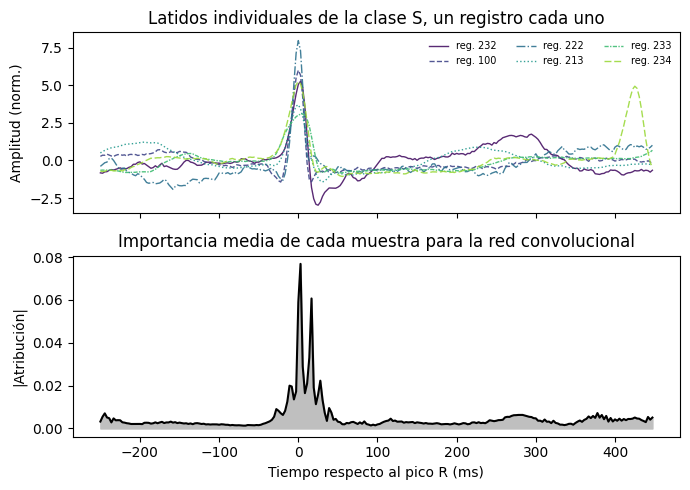

Clase S: registros mostrados [np.int64(232), np.int64(100), np.int64(222), np.int64(213), np.int64(233), np.int64(234)]


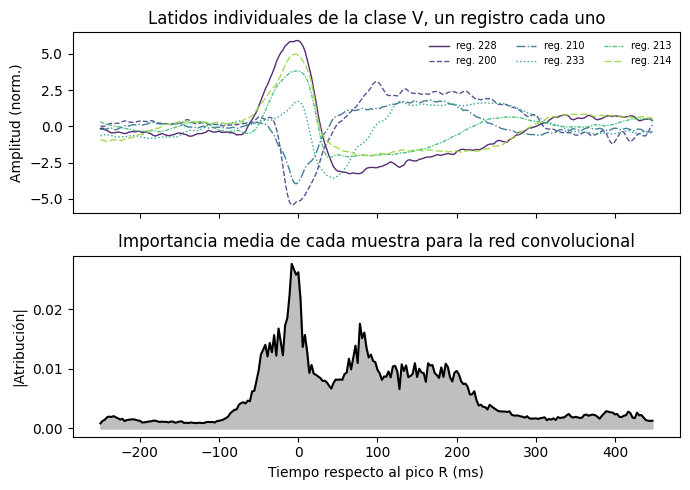

Clase V: registros mostrados [np.int64(228), np.int64(200), np.int64(210), np.int64(233), np.int64(213), np.int64(214)]


In [ ]:
import tensorflow as tf
rng = np.random.default_rng(0)

def atribuciones(f, r, clase, n=64):
    idx = rng.integers(0, len(d['Vtr']), n)
    bf = d['Vtr'][idx][..., None].astype('float32'); br = d['Rtr'][idx].astype('float32')
    fb = np.repeat(f[None, :, None], n, axis=0).astype('float32')
    rb = np.repeat(r[None, :], n, axis=0).astype('float32')
    al = rng.random((n,1,1)).astype('float32')
    tf_f = tf.Variable(bf + al*(fb-bf)); tf_r = tf.Variable(br + al[:,:,0]*(rb-br))
    with tf.GradientTape() as cinta:
        cinta.watch([tf_f, tf_r]); y = modelo([tf_f, tf_r])[:, clase]
    gf, _ = cinta.gradient(y, [tf_f, tf_r])
    return np.mean(gf.numpy()[:,:,0] * (fb-bf)[:,:,0], axis=0)

N_TRAZOS = 6
for cl in ['S', 'V']:
    i = a_numero[cl]
    ok = np.where((d['yp'] == i) & (d['pred'] == i))[0]

    # un latido por registro distinto, hasta N_TRAZOS registros
    regs, elegidos = [], []
    for j in rng.permutation(ok):
        g = d['regp'][j]
        if g not in regs:
            regs.append(g); elegidos.append(j)
        if len(elegidos) == N_TRAZOS: break

    muestra = rng.choice(ok, min(120, len(ok)), replace=False)
    A = np.zeros(252)
    for k in muestra: A += np.abs(atribuciones(d['Vp'][k], d['Rp'][k], i))
    A /= len(muestra)

    fig, ax = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
    for j, g in zip(elegidos, regs):
        ax[0].plot(ms, d['Vp'][j], lw=0.9, alpha=0.85, label=f'reg. {g}')
    ax[0].set_ylabel('Amplitud (norm.)')
    ax[0].set_title(f'Latidos individuales de la clase {cl}, un registro cada uno')
    ax[0].legend(fontsize=7, ncol=3, frameon=False)
    ax[1].plot(ms, A, color='k'); ax[1].fill_between(ms, 0, A, color='0.75')
    ax[1].set_ylabel('|Atribución|'); ax[1].set_xlabel('Tiempo respecto al pico R (ms)')
    ax[1].set_title('Importancia media de cada muestra para la red convolucional')
    plt.tight_layout()
    plt.savefig(f'figura2_{cl}.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Clase {cl}: registros mostrados {regs}')

## 9. Descargar

In [ ]:
from google.colab import files
import glob
for a in ['p13_filtro.csv', 'p13_segmentos.csv', 'p13_oclusion.csv'] + sorted(glob.glob('figura2_*.png')):
    files.download(a)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>